# EDA: Amazon Reviews 2023, Video_Games

Цель — понять данные до выбора моделей: распределение активности, хвост
каталога, повторные покупки и пригодность категорий для 5-core протокола.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recsys.config import ARTIFACTS_DIR, PROCESSED_DIR

CATEGORY = "Video_Games"
PROCESSED = PROCESSED_DIR / CATEGORY
FIG_DIR = ARTIFACTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": 0.3})
train = pd.read_parquet(PROCESSED / "train.parquet")
valid = pd.read_parquet(PROCESSED / "valid.parquet")
test = pd.read_parquet(PROCESSED / "test.parquet")
items = pd.read_parquet(PROCESSED / "items.parquet")
stats = json.loads((PROCESSED / "stats.json").read_text())
print({k: stats[k] for k in ("users", "items", "train", "valid", "test")})

{'users': 98906, 'items': 26354, 'train': 628416, 'valid': 95268, 'test': 95268}


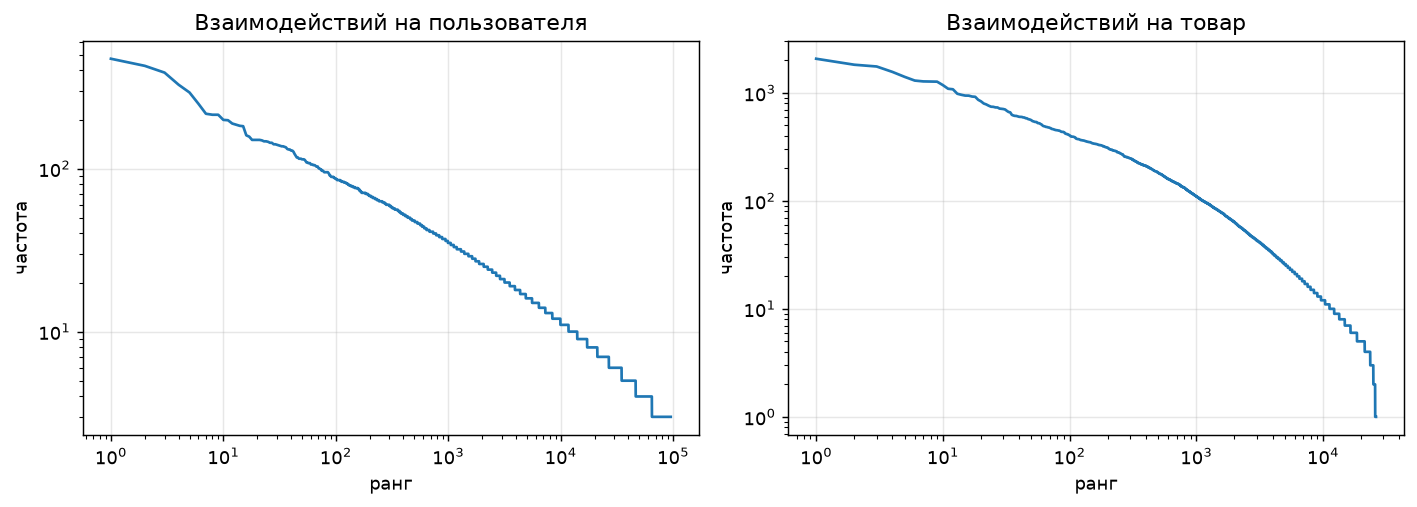

пользователи: {'count': 95268.0, 'mean': 6.6, 'std': 7.9, 'min': 3.0, '50%': 4.0, '90%': 12.0, '99%': 36.0, 'max': 472.0}
товары: {'count': 26196.0, 'mean': 23.99, 'std': 59.88, 'min': 1.0, '50%': 9.0, '90%': 49.0, '99%': 267.1, 'max': 2069.0}


In [2]:
# Активность: длинный хвост пользователей и товаров — типичный e-commerce.
user_counts = train.groupby("user_id").size()
item_counts = train.groupby("item_id").size()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title in (
    (axes[0], user_counts, "Взаимодействий на пользователя"),
    (axes[1], item_counts, "Взаимодействий на товар"),
):
    values = np.sort(counts.values)[::-1]
    ax.loglog(np.arange(1, len(values) + 1), values)
    ax.set_title(title)
    ax.set_xlabel("ранг")
    ax.set_ylabel("частота")
fig.tight_layout()
fig.savefig(FIG_DIR / "activity_long_tail.png", bbox_inches="tight")
plt.show()

print("пользователи:", user_counts.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_dict())
print("товары:", item_counts.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_dict())

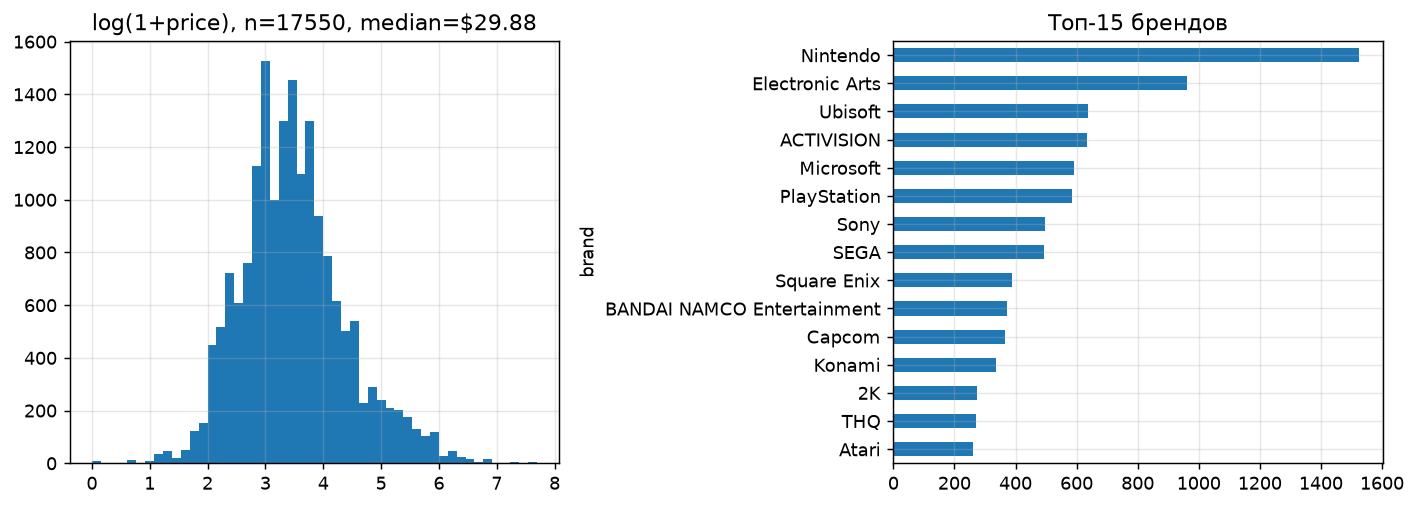

доля товаров с брендом: 99.5%
доля товаров с ценой: 66.6%


In [3]:
# Метаданные: чем богаче карточка, тем полезнее content-based.
price = items["price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log1p(price), bins=50)
axes[0].set_title(f"log(1+price), n={len(price)}, median=${price.median():.2f}")
items["brand"].replace("", pd.NA).dropna().value_counts().head(15)[::-1].plot.barh(
    ax=axes[1], title="Топ-15 брендов"
)
fig.tight_layout()
fig.savefig(FIG_DIR / "catalog_meta.png", bbox_inches="tight")
plt.show()

print("доля товаров с брендом:", f"{(items['brand'] != '').mean():.1%}")
print("доля товаров с ценой:", f"{items['price'].notna().mean():.1%}")

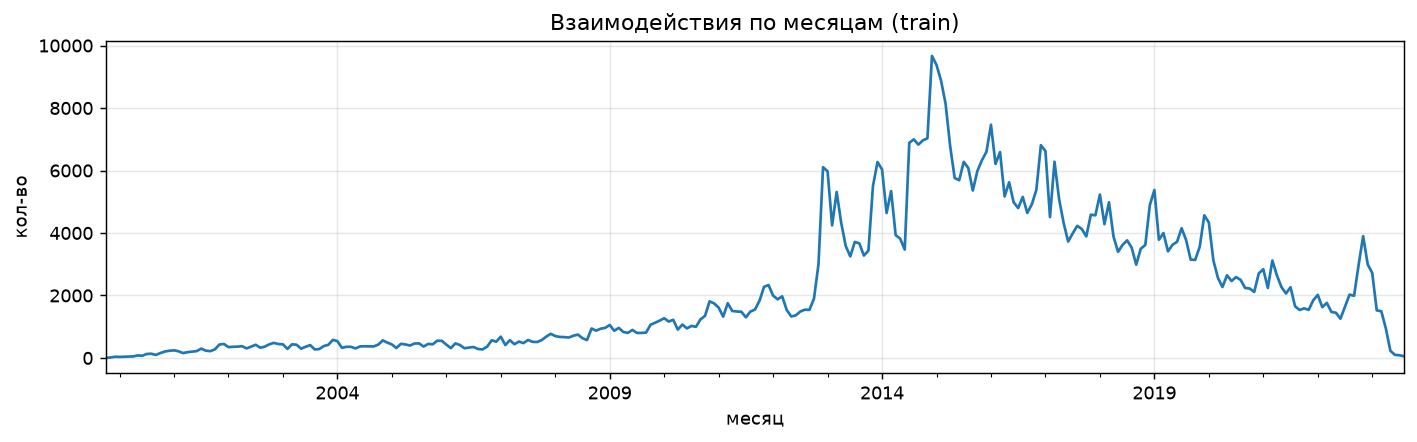

train: 1999-10-22 -> 2023-08-29


In [4]:
# Время: проверяем, что сплит по времени не оставляет будущее в train.
timestamps = pd.to_datetime(train["timestamp"], unit="ms")
monthly = timestamps.dt.to_period("M").value_counts().sort_index()
ax = monthly.plot(figsize=(11, 3.5), title="Взаимодействия по месяцам (train)")
ax.set_xlabel("месяц")
ax.set_ylabel("кол-во")
plt.tight_layout()
plt.savefig(FIG_DIR / "timeline.png", bbox_inches="tight")
plt.show()
print("train:", timestamps.min().date(), "->", timestamps.max().date())

In [5]:
# Повторные покупки: сколько тестовых покупок — повтор уже купленного.
train_pairs = set(zip(train["user_id"], train["item_id"], strict=True))
repeat_item = np.mean(
    [(u, i) in train_pairs for u, i in zip(test["user_id"], test["item_id"], strict=True)]
)

brand = items.set_index("item_id")["brand"]
train_brands = set(zip(train["user_id"], brand.reindex(train["item_id"]).to_numpy(), strict=True))
repeat_brand = np.mean(
    [
        (u, b) in train_brands
        for u, b in zip(test["user_id"], brand.reindex(test["item_id"]), strict=True)
        if isinstance(b, str) and b
    ]
)
print(f"доля повторных товаров в тесте: {repeat_item:.2%}")
print("  (0% по построению: дубликаты user-item удалены перед сплитом,")
print("   поэтому протокол измеряет discovery, а не repurchase)")
print(f"доля тестовых покупок того же бренда: {repeat_brand:.2%}")

доля повторных товаров в тесте: 0.00%
  (0% по построению: дубликаты user-item удалены перед сплитом,
   поэтому протокол измеряет discovery, а не repurchase)
доля тестовых покупок того же бренда: 24.50%


In [6]:
# Почему не All_Beauty: 5-core схлопывает категорию.
ab = json.loads((PROCESSED_DIR / "All_Beauty" / "stats.json").read_text())
print("All_Beauty после 5-core:", {k: ab[k] for k in ("users", "items", "train")})
print("Video_Games после 5-core:", {k: stats[k] for k in ("users", "items", "train")})

All_Beauty после 5-core: {'users': 357, 'items': 479, 'train': 2216}
Video_Games после 5-core: {'users': 98906, 'items': 26354, 'train': 628416}


## Выводы EDA

- Распределения активности и популярности — степенные: топ-1% товаров даёт
  значимую долю взаимодействий, поэтому popularity-baseline силён, а coverage
  и novelty нужно смотреть вместе с accuracy.
- Каталог хорошо покрыт метаданными (бренд, цена), значит content-based и
  эвристики «тот же бренд» имеют смысл.
- Повторные покупки в тесте — отдельный бизнес-кейс: для него нужен
  блок «недавно просмотренные / купить снова», который не измеряется
  leave-last-out протоколом.
- All_Beauty после 5-core непригодна для статистики (357 пользователей),
  поэтому основной датасет — Video_Games.